In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report


In [2]:
# 1. Đọc và in dữ liệu
df = pd.read_csv('BT6.User_Data.csv')

print("=== 5 DÒNG ĐẦU TIÊN CỦA DỮ LIỆU ===")
display(df.head())

print("\n=== THÔNG TIN DỮ LIỆU ===")
df.info()


=== 5 DÒNG ĐẦU TIÊN CỦA DỮ LIỆU ===


,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0



=== THÔNG TIN DỮ LIỆU ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   User ID          400 non-null    int64 
 1   Gender           400 non-null    object
 2   Age              400 non-null    int64 
 3   EstimatedSalary  400 non-null    int64 
 4   Purchased        400 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 15.8+ KB


In [3]:
# 2. Gán X là Age và EstimatedSalary; y là Purchased
X = df[['Age', 'EstimatedSalary']]
y = df['Purchased']

print("Kích thước ma trận X:", X.shape)
print("Kích thước vector y  :", y.shape)
print("\n5 dòng đầu của X:")
display(X.head())


Kích thước ma trận X: (400, 2)
Kích thước vector y  : (400,)

5 dòng đầu của X:


,Age,EstimatedSalary
0,19,19000
1,35,20000
2,26,43000
3,27,57000
4,19,76000


In [4]:
# 3. Chuẩn hóa miền giá trị của X bằng StandardScaler
scaler = StandardScaler()
X = scaler.fit_transform(X)

print("Dữ liệu X sau khi chuẩn hóa (5 dòng đầu):")
print(X[:5])


Dữ liệu X sau khi chuẩn hóa (5 dòng đầu):
[[-1.78179743 -1.49004624]
 [-0.25358736 -1.46068138]
 [-1.11320552 -0.78528968]
 [-1.01769239 -0.37418169]
 [-1.78179743  0.18375059]]


In [5]:
# 4. Chia X, y thành tập train và test với tỷ lệ 8-2
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

print("Kích thước tập X_train:", X_train.shape)
print("Kích thước tập X_test :", X_test.shape)
print("Kích thước tập y_train:", y_train.shape)
print("Kích thước tập y_test :", y_test.shape)


Kích thước tập X_train: (320, 2)
Kích thước tập X_test : (80, 2)
Kích thước tập y_train: (320,)
Kích thước tập y_test : (80,)


In [6]:
# 5. Khởi tạo mô hình Logistic Regression và huấn luyện trên tập X_train
model = LogisticRegression(random_state=0)
model.fit(X_train, y_train)

print("Đã huấn luyện xong mô hình Logistic Regression!")


Đã huấn luyện xong mô hình Logistic Regression!


In [7]:
# 6. Dự đoán giá trị y_pred trên tập test
y_pred = model.predict(X_test)

df_result = pd.DataFrame({
    'Thực tế (y_test)': y_test.values,
    'Dự đoán (y_pred)': y_pred
})

print("So sánh giá trị thực tế và dự đoán (10 dòng đầu):")
display(df_result.head(10))


So sánh giá trị thực tế và dự đoán (10 dòng đầu):


,Thực tế (y_test),Dự đoán (y_pred)
0,0,0
1,0,0
2,0,0
3,0,0
4,0,0
5,0,0
6,0,0
7,1,1
8,0,0
9,0,0


In [8]:
# 7. In ra các hệ số của mô hình hồi quy: intercept và slope (coef)
print("Hệ số chặn (Intercept):", model.intercept_[0])
print("Hệ số góc (Slope / Coef) [Age, EstimatedSalary]:", model.coef_[0])

print("\n=== NHẬN XÉT HỆ SỐ ===")
print("- Hệ số chặn beta_0 =", round(model.intercept_[0], 4))
print("- Hệ số của Age beta_1 =", round(model.coef_[0][0], 4))
print("- Hệ số của EstimatedSalary beta_2 =", round(model.coef_[0][1], 4))
print("=> Nhận xét:")
print("• Cả 2 hệ số beta_1 và beta_2 đều mang giá trị dương (> 0), cho thấy cả độ tuổi và mức lương ước tính đều tỉ lệ thuận với quyết định mua hàng (khách hàng càng lớn tuổi và lương càng cao thì xác suất mua hàng càng cao).")
print("• Hệ số của Age (2.0347) lớn hơn hệ số của EstimatedSalary (1.0664), cho thấy độ tuổi có mức độ ảnh hưởng mạnh hơn đến quyết định mua hàng so với mức lương.")


Hệ số chặn (Intercept): -0.985050968203747
Hệ số góc (Slope / Coef) [Age, EstimatedSalary]: [2.03470688 1.06640379]

=== NHẬN XÉT HỆ SỐ ===
- Hệ số chặn beta_0 = -0.9851
- Hệ số của Age beta_1 = 2.0347
- Hệ số của EstimatedSalary beta_2 = 1.0664
=> Nhận xét:
• Cả 2 hệ số beta_1 và beta_2 đều mang giá trị dương (> 0), cho thấy cả độ tuổi và mức lương ước tính đều tỉ lệ thuận với quyết định mua hàng (khách hàng càng lớn tuổi và lương càng cao thì xác suất mua hàng càng cao).
• Hệ số của Age (2.0347) lớn hơn hệ số của EstimatedSalary (1.0664), cho thấy độ tuổi có mức độ ảnh hưởng mạnh hơn đến quyết định mua hàng so với mức lương.


Ma trận nhầm lẫn (Confusion Matrix):
[[57  1]
 [ 5 17]]


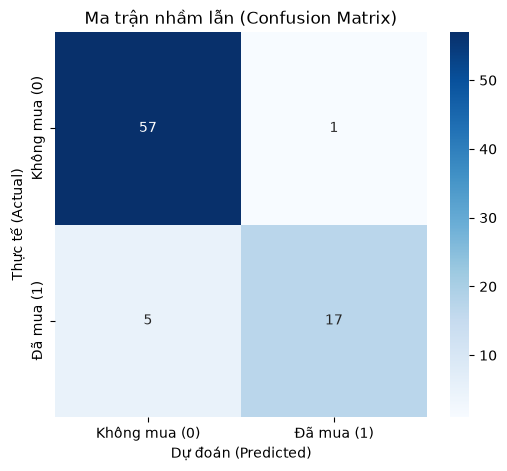

In [9]:
# 8. In ra ma trận nhầm lẫn (Confusion Matrix) và vẽ bằng heatmap
cm = confusion_matrix(y_test, y_pred)
print("Ma trận nhầm lẫn (Confusion Matrix):")
print(cm)

# Vẽ ma trận nhầm lẫn bằng heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Không mua (0)', 'Đã mua (1)'],
            yticklabels=['Không mua (0)', 'Đã mua (1)'])
plt.title('Ma trận nhầm lẫn (Confusion Matrix)')
plt.xlabel('Dự đoán (Predicted)')
plt.ylabel('Thực tế (Actual)')
plt.show()


In [10]:
# 9. In kết quả Accuracy, Precision, Recall và Weighted Metrics
print("Báo cáo phân lớp (Classification Report):")
print(classification_report(y_test, y_pred, target_names=['Không mua (0)', 'Đã mua (1)'], digits=4))

print("\n=== NHẬN XÉT KẾT QUẢ TRÊN TỪNG LỚP ===")
print("1. Độ chính xác tổng thể (Accuracy): đạt 92.50% (dự đoán đúng 74/80 mẫu trên tập test), mô hình có hiệu quả phân loại rất tốt.")
print("2. Lớp 0 (Khách hàng không mua):")
print("   - Precision = 91.94%: Trong các trường hợp mô hình dự đoán là 'Không mua', có 91.94% là đúng.")
print("   - Recall = 98.28%: Mô hình nhận diện chính xác 57/58 người thực tế không mua, chỉ bỏ sót nhầm 1 người.")
print("   - F1-Score = 0.9500: Kết quả phân loại lớp 0 gần như hoàn hảo.")
print("3. Lớp 1 (Khách hàng đã mua):")
print("   - Precision = 94.44%: Khi mô hình dự đoán khách hàng 'Sẽ mua', độ tin cậy rất cao (17/18 người đoán đúng).")
print("   - Recall = 77.27%: Mô hình nhận diện được 17/22 người có mua thực tế, bị bỏ sót 5 người.")
print("   - F1-Score = 0.8500: Đạt mức cân bằng tốt.")
print("4. Các chỉ số trung bình gia quyền (Weighted):")
print("   - Weighted Precision = 92.63%, Weighted Recall = 92.50%, Weighted F1-score = 92.25%.")
print("   - Các chỉ số Weighted đều đạt trên 92%, cho thấy mô hình phân loại đồng đều và ổn định.")


Báo cáo phân lớp (Classification Report):
               precision    recall  f1-score   support

Không mua (0)     0.9194    0.9828    0.9500        58
   Đã mua (1)     0.9444    0.7727    0.8500        22

     accuracy                         0.9250        80
    macro avg     0.9319    0.8777    0.9000        80
 weighted avg     0.9263    0.9250    0.9225        80


=== NHẬN XÉT KẾT QUẢ TRÊN TỪNG LỚP ===
1. Độ chính xác tổng thể (Accuracy): đạt 92.50% (dự đoán đúng 74/80 mẫu trên tập test), mô hình có hiệu quả phân loại rất tốt.
2. Lớp 0 (Khách hàng không mua):
   - Precision = 91.94%: Trong các trường hợp mô hình dự đoán là 'Không mua', có 91.94% là đúng.
   - Recall = 98.28%: Mô hình nhận diện chính xác 57/58 người thực tế không mua, chỉ bỏ sót nhầm 1 người.
   - F1-Score = 0.9500: Kết quả phân loại lớp 0 gần như hoàn hảo.
3. Lớp 1 (Khách hàng đã mua):
   - Precision = 94.44%: Khi mô hình dự đoán khách hàng 'Sẽ mua', độ tin cậy rất cao (17/18 người đoán đúng).
   - Recall = 77